# Bands Read Input 
Reads a `.bands` file from quantum espresso so that you have a k_points array and a band_energies array.

In [44]:
import numpy as np


def get_blochgrid(file):
    """
    File reading utility. Reads a '.bands` file from Quantum Espresso to return k-points and bloch energies. 
    
    Args:
        file: file path.
        
        
    Returns:
        k_points: k point grid. Shape of the array is equal to #kpoints on the grid times 3. 
        band_energies: bloch energies. Shape of array is #kpoints times #bands. Each column corresponds to one band.
    """
    
    # Initialize lists to store the k-points and band energies
    k_points = []
    band_energies = []

    whitespace = ' '*5

    with open(file, 'r') as f:
        lines = f.readlines()

        line0 = lines[0].replace(',', '').strip().split()
        nbnd, nks = int(line0[2]), int(line0[4])

        for line in lines[1:]:
            if line[0:5] == whitespace:
                parts = line.strip().split()
                k_points.append([float(x) for x in parts])

            else:
                parts = line.strip().split()
                band_energies.append([float(x) for x in parts])


    k_pointsflat = np.array([x for kpoint in k_points for x in kpoint])
    k_points =k_pointsflat.reshape(-1,3)

    band_energyflat = np.array([x for bandenergy in band_energies for x in bandenergy])
    band_energies = band_energyflat.reshape(-1,nbnd)

#     print(f"k_points_array shape: {k_points.shape}")
#     print(f"band_energies_array shape: {band_energies.shape}")

    return k_points, band_energies

In [87]:
k_points, band_energies = get_blochgrid('data/gr.bands')

In [89]:
k_points[:,0].shape

(91,)

In [56]:
d = np.array([k_points[:,0], k_points[:,1], band_energies[:,0]]).T

In [95]:
 k_points[:,0]

array([0.      , 0.016667, 0.033333, 0.05    , 0.066667, 0.083333,
       0.1     , 0.116667, 0.133333, 0.15    , 0.166667, 0.183333,
       0.2     , 0.216667, 0.233333, 0.25    , 0.266667, 0.283333,
       0.3     , 0.316667, 0.333333, 0.35    , 0.366667, 0.383333,
       0.4     , 0.416667, 0.433333, 0.45    , 0.466667, 0.483333,
       0.5     , 0.516667, 0.533333, 0.55    , 0.566667, 0.583333,
       0.6     , 0.616667, 0.633333, 0.65    , 0.666667, 0.658333,
       0.65    , 0.641667, 0.633333, 0.625   , 0.616667, 0.608333,
       0.6     , 0.591667, 0.583333, 0.575   , 0.566667, 0.558333,
       0.55    , 0.541667, 0.533333, 0.525   , 0.516667, 0.508333,
       0.5     , 0.483333, 0.466667, 0.45    , 0.433333, 0.416667,
       0.4     , 0.383333, 0.366667, 0.35    , 0.333333, 0.316667,
       0.3     , 0.283333, 0.266667, 0.25    , 0.233333, 0.216667,
       0.2     , 0.183333, 0.166667, 0.15    , 0.133333, 0.116667,
       0.1     , 0.083333, 0.066667, 0.05    , 0.033333, 0.016

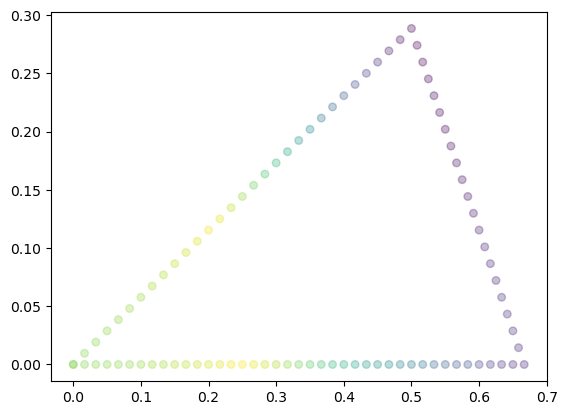

In [106]:
plt.scatter(x = k_points[:,0], y = k_points[:,1], c = 'blue', s = 10* band_energies[:,0], alpha = 0.6)
plt.scatter(x = k_points[:,0], y = k_points[:,1], c = band_energies[:,1], s = 30, alpha = 0.3)

In [108]:
k_points[:,0]**2+k_points[:,1]**2

array([0.00000000e+00, 2.77788889e-04, 1.11108889e-03, 2.50000000e-03,
       4.44448889e-03, 6.94438889e-03, 1.00000000e-02, 1.36111889e-02,
       1.77776889e-02, 2.25000000e-02, 2.77778889e-02, 3.36109889e-02,
       4.00000000e-02, 4.69445889e-02, 5.44442889e-02, 6.25000000e-02,
       7.11112889e-02, 8.02775889e-02, 9.00000000e-02, 1.00277989e-01,
       1.11110889e-01, 1.22500000e-01, 1.34444689e-01, 1.46944189e-01,
       1.60000000e-01, 1.73611389e-01, 1.87777489e-01, 2.02500000e-01,
       2.17778089e-01, 2.33610789e-01, 2.50000000e-01, 2.66944789e-01,
       2.84444089e-01, 3.02500000e-01, 3.21111489e-01, 3.40277389e-01,
       3.60000000e-01, 3.80278189e-01, 4.01110689e-01, 4.22500000e-01,
       4.44444889e-01, 4.33610679e-01, 4.23333361e-01, 4.13611515e-01,
       4.04444019e-01, 3.95833365e-01, 3.87778268e-01, 3.80277312e-01,
       3.73333321e-01, 3.66944888e-01, 3.61110847e-01, 3.55833230e-01,
       3.51111461e-01, 3.46944133e-01, 3.43333497e-01, 3.40277987e-01,
      

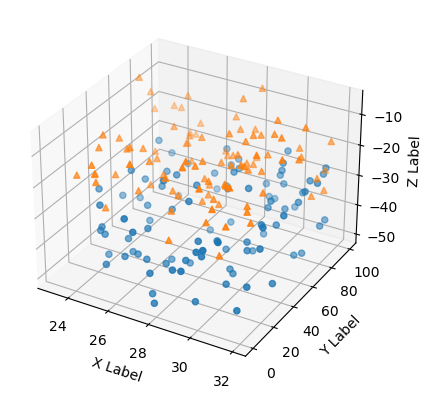

In [48]:
import matplotlib.pyplot as plt
import numpy as np

# Fixing random state for reproducibility
np.random.seed(19680801)


def randrange(n, vmin, vmax):
    """
    Helper function to make an array of random numbers having shape (n, )
    with each number distributed Uniform(vmin, vmax).
    """
    return (vmax - vmin)*np.random.rand(n) + vmin

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

n = 100

# For each set of style and range settings, plot n random points in the box
# defined by x in [23, 32], y in [0, 100], z in [zlow, zhigh].
for m, zlow, zhigh in [('o', -50, -25), ('^', -30, -5)]:
    xs = randrange(n, 23, 32)
    ys = randrange(n, 0, 100)
    zs = randrange(n, zlow, zhigh)
    ax.scatter(xs, ys, zs, marker=m)

ax.set_xlabel('X Label')
ax.set_ylabel('Y Label')
ax.set_zlabel('Z Label')

plt.show()